# Realistic fraudsters in SynCCFD

This notebook shows the **injected** frauds of SynCCFD: the fraudster makes **new**
transactions, added to the customer's own ones; legitimate transactions are never altered
nor labelled as fraud.

| # | scenario | what the fraudster does |
|---|---|---|
| 1 | anomalous amount | one purchase far above the customer's recent history: $2 \times$ the 95% quantile of the purchases of the last 30 days, times $1 + 0.5\,U$ |
| 2 | compromised terminal | a terminal compromised for 28 days reads the card of whoever buys there (the purchase stays legitimate); 1 to 14 days later, 20% of the read cards are cloned (CP purchases in sequence near the fraudster) and 5% go to scenario 3 |
| 3 | stolen card number | bursts of 2 to 5 CNP purchases within 3 h, shipped to the fraudster's address, more frequent at night, with amounts around $2 \times$ the customer's recent median |
| 4 | stolen physical card | purchases in sequence (every 20 min on average) near the victim's city, until the card is blocked, the spending limit is reached or 24 h have passed |
| 5 | card testing | 3 to 10 CNP purchases of R\$ 1 to 5 within minutes; in half of the cases, the fraudster goes on to scenario 3 with the same card |

`FraudConfig.realistic()` switches the five scenarios on, with rates proportional to the
population and fraudster drift: scenario 2 halves from 60% of the period on (chip) and
scenario 5 appears from 30% on.

`LANG` is the language of the figure labels: `"en"` (default) or `"pt"`; the environment
variable `SYNCCFD_LANG` sets it. The figures are saved as PDF in `figures/frauds/`
(`SYNCCFD_FIG_DIR` changes `figures/`).

In [1]:
import os
import re
from pathlib import Path

# Fixed creation date in the PDF files: an unchanged figure is written byte for byte
# the same
os.environ.setdefault("SOURCE_DATE_EPOCH", "0")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import ticker

from synccfd import DatasetGenerator
from synccfd.simulator import presets
from synccfd.simulator.config import MerchantConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight
from synccfd.simulator.ground_truth import compromise_table

# Language of the figure labels: "en" or "pt"
LANG = os.environ.get("SYNCCFD_LANG", "en")
TEXT = {
    "en": {
        "scenarios": {
            1: "1 · anomalous amount",
            2: "2 · compromised terminal",
            3: "3 · stolen card number",
            4: "4 · stolen physical card",
            5: "5 · card testing",
        },
        "half_rate": "half the rate (chip)",
        "card_testing_start": "start of card testing",
        "share_of_tx": "% of the\ntransactions",
        "day": "day",
        "seeds_note": "Line: mean of {n} seeds; band: from the lowest to the highest seed.",
        "victim_purchases": "the victim's legitimate purchases",
        "hours_since_test": "hours since the first test",
        "amount_log": "amount (R$, log scale)",
        "campaign_title": "campaign {campaign}, customer {customer}",
        "minutes_since_test": "minutes since the first test",
        "amount": "amount (R$)",
        "tests_title": "the {n} tests",
        "legitimate": "legitimate",
        "median": "median",
        "boxes_note": "amount (R$, log scale); boxes: quartiles; whiskers: up to 1.5 × IQR (in log)",
        "no_merchants": "Without merchants",
        "full_dataset": "With merchants (full dataset)",
        "share_labels": ["legitimate transactions\nin regime B",
                         "fixed-threshold label rule\n(R$ 220): labelled, in regime B",
                         "injected fraud (scenario 1):\nvictims in regime B"],
        "share_of_row": "% of the transactions of the row",
        "migration": "migration (50% of the period)",
        "share_of_s3": "% of the purchases of scenario 3",
        # Values of the data, shown translated in the English figures
        "categories": {
            "supermercado": "supermarket", "restaurante_bar": "restaurant and bar",
            "posto_combustivel": "fuel station", "farmacia": "pharmacy",
            "vestuario": "clothing", "eletronicos": "electronics",
            "viagem_turismo": "travel", "ecommerce_marketplace": "marketplace",
            "servicos_digitais": "digital services", "transporte_app": "ride-hailing",
        },
    },
    "pt": {
        "scenarios": {
            1: "1 · valor anômalo",
            2: "2 · terminal comprometido",
            3: "3 · número do cartão roubado",
            4: "4 · cartão físico roubado",
            5: "5 · card testing",
        },
        "half_rate": "metade da taxa (chip)",
        "card_testing_start": "início do card testing",
        "share_of_tx": "% das\ntransações",
        "day": "dia",
        "seeds_note": "Linha: média de {n} sementes; faixa: da menor à maior semente.",
        "victim_purchases": "compras legítimas da vítima",
        "hours_since_test": "horas desde o primeiro teste",
        "amount_log": "valor (R$, escala log)",
        "campaign_title": "campanha {campaign}, cliente {customer}",
        "minutes_since_test": "minutos desde o primeiro teste",
        "amount": "valor (R$)",
        "tests_title": "os {n} testes",
        "legitimate": "legítimas",
        "median": "mediana",
        "boxes_note": "valor (R$, escala log); caixas: quartis; hastes: até 1,5 × IQR (em log)",
        "no_merchants": "Sem comerciantes",
        "full_dataset": "Com comerciantes (conjunto completo)",
        "share_labels": ["transações legítimas\nno regime B",
                         "regra de rótulo por limiar fixo\n(R$ 220): rotuladas do regime B",
                         "fraude injetada (cenário 1):\nvítimas no regime B"],
        "share_of_row": "% das transações da linha",
        "migration": "migração (50% do período)",
        "share_of_s3": "% das compras do cenário 3",
        "categories": {},  # as in the data
    },
}
T = TEXT[LANG]

# Where the figures are saved
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "figures")) / "frauds"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette, in fixed order (one color per scenario)
SCENARIO_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4"}
SCENARIO_NAMES = T["scenarios"]
MUTED, INK, SECONDARY = "#8a8985", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

# In Portuguese, the numbers in the figures use the decimal comma and a space between
# the thousands, as in the text of the dissertation
def num(text):
    if LANG != "pt":
        return text
    math = text.count("$") >= 2  # mathtext: braces keep the comma without a space
    point, thousands = ("{,}", r"\,") if math else (",", "\u00a0")
    return re.sub(r"(?<=\d)[.,](?=\d)", lambda m: point if m.group() == "." else thousands, text)


class LocalizedFormatter(ticker.Formatter):
    # The labels of another tick formatter, through num()
    def __init__(self, inner):
        self.inner = inner

    def set_axis(self, axis):
        self.axis = axis
        self.inner.set_axis(axis)

    def set_locs(self, locs):
        self.inner.set_locs(locs)

    def __call__(self, x, pos=None):
        return num(self.inner(x, pos))

    def format_ticks(self, values):
        return [num(label) for label in self.inner.format_ticks(values)]

    def get_offset(self):
        return num(self.inner.get_offset())


def localize(fig):
    # The tick labels of every axis through num(); call it just before saving
    if LANG != "pt":
        return
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            if not isinstance(axis.get_major_formatter(), LocalizedFormatter):
                axis.set_major_formatter(LocalizedFormatter(axis.get_major_formatter()))
            if not isinstance(axis.get_minor_formatter(), LocalizedFormatter):
                axis.set_minor_formatter(LocalizedFormatter(axis.get_minor_formatter()))

## Generation

The dataset is `presets.realistic()`, with `FraudConfig.realistic()`, customer drift
(30%), seasonality and merchants.

In [2]:
# The preset of the notebooks; the SYNCCFD_* variables change it
PARAMS = presets.from_env()
fraud = PARAMS["fraud"]
assert fraud is not None and 5 in fraud.scenarios, "this notebook needs the five fraud scenarios"
N_CUSTOMERS, N_TERMINALS, NB_DAYS, SEED = (
    PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days", "random_state")
)
customers, terminals, transactions = DatasetGenerator(**PARAMS).generate()
frauds = transactions[transactions.TX_FRAUD == 1]
print(f"{len(transactions):,} transactions; fraud rate {transactions.TX_FRAUD.mean():.3%}")
summary = frauds.groupby("TX_FRAUD_SCENARIO").agg(
    transactions=("TRANSACTION_ID", "size"), campaigns=("GT_CAMPAIGN_ID", "nunique"),
    median_amount=("TX_AMOUNT", "median"),
)
summary["rate_%"] = 100 * summary.transactions / len(transactions)
summary.rename(index=SCENARIO_NAMES).round(3)

3,735,430 transactions; fraud rate 0.356%


,transactions,campaigns,median_amount,rate_%
TX_FRAUD_SCENARIO,,,,
1 · anomalous amount,527,527,1602.03,0.014
2 · compromised terminal,1165,235,121.87,0.031
3 · stolen card number,7274,720,272.94,0.195
4 · stolen physical card,2623,547,116.08,0.070
5 · card testing,1694,256,3.03,0.045


## Rate per scenario over time

Weekly share of the transactions that are frauds of each scenario. The vertical lines mark
the fraudster drift: the fall of scenario 2 (60% of the period) and the start of
scenario 5 (30%).

Even with 10 000 customers, each scenario has few attacks per day (about 1 compromised
terminal per day, for example), and the number of purchases per terminal is very uneven.
In a single dataset, the weekly curve oscillates a lot and can suggest trends that do not
exist. So the figure shows the mean of 10 seeds (line) and the band between the lowest and
the highest seed.

In [3]:
SEEDS = range(SEED, SEED + 10)
n_weeks = NB_DAYS // 7  # the last, partial week is left out


def weekly_rates(data):
    # % of each week's transactions that are fraud of each scenario
    week = data.TX_TIME_DAYS // 7
    keep = week < n_weeks
    counts = pd.crosstab(week[keep], data.TX_FRAUD_SCENARIO[keep])
    return 100 * counts.div(counts.sum(axis=1), axis=0).reindex(columns=range(6), fill_value=0)


rates = [weekly_rates(transactions)]
for seed in SEEDS[1:]:
    _, _, other = DatasetGenerator(**{**PARAMS, "random_state": seed}).generate()
    rates.append(weekly_rates(other))
    del other

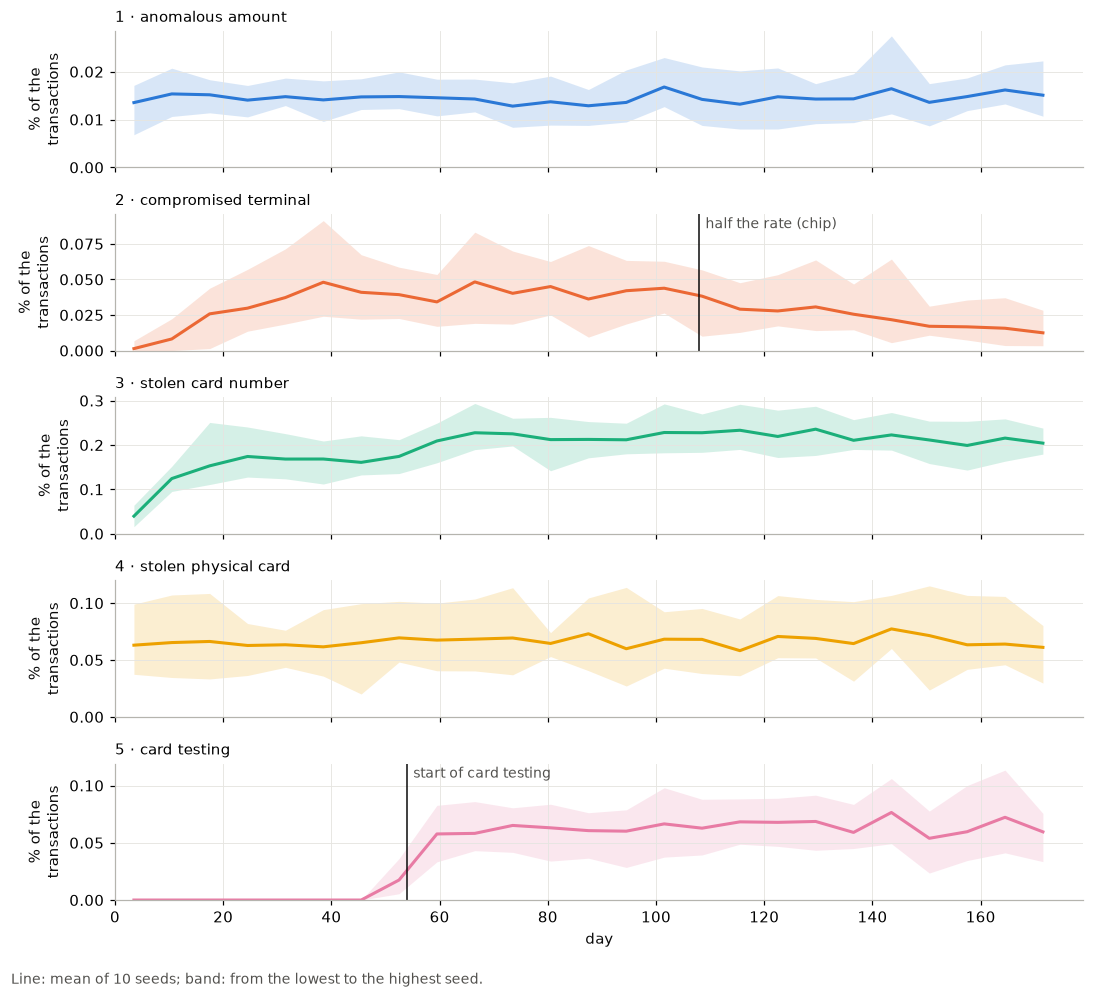

In [4]:
changes = {2: 0.6 * NB_DAYS, 5: 0.3 * NB_DAYS}
days = np.arange(n_weeks) * 7 + 3.5

fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
for ax, scenario in zip(axes, SCENARIO_NAMES):
    per_seed = np.vstack([r[scenario].to_numpy() for r in rates])
    color = SCENARIO_COLORS[scenario]
    ax.fill_between(days, per_seed.min(axis=0), per_seed.max(axis=0), color=color, alpha=0.18, lw=0)
    ax.plot(days, per_seed.mean(axis=0), color=color, lw=2)
    if scenario in changes:
        ax.axvline(changes[scenario], color=INK, lw=1)
        ax.annotate(
            T["half_rate"] if scenario == 2 else T["card_testing_start"],
            (changes[scenario], 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color=SECONDARY,
        )
    ax.set_ylim(bottom=0)
    ax.set_title(SCENARIO_NAMES[scenario], loc="left", fontsize=10)
    ax.set_ylabel(T["share_of_tx"])
axes[-1].set_xlabel(T["day"])
axes[-1].set_xlim(0, NB_DAYS - 1)
fig.text(0.01, 0.0, T["seeds_note"].format(n=len(rates)), fontsize=9, color=SECONDARY)
fig.tight_layout(rect=(0, 0.02, 1, 1))
localize(fig)
fig.savefig(FIG_DIR / "frauds_rate_by_scenario.pdf", bbox_inches="tight")
plt.show()

## One campaign: card testing → stolen card number

A campaign in which the fraudster tests the card (scenario 5) and then uses it in CNP
purchases (scenario 3), with the same `GT_CAMPAIGN_ID`. In grey, the victim's legitimate
purchases in the same period, which go on as usual.

In [5]:
by_campaign = frauds.groupby("GT_CAMPAIGN_ID")
scenarios_in = by_campaign.TX_FRAUD_SCENARIO.agg(set)
escalated = scenarios_in[scenarios_in.apply(lambda s: s == {3, 5})].index
bursts = frauds[frauds.GT_CAMPAIGN_ID.isin(escalated) & (frauds.TX_FRAUD_SCENARIO == 3)]
# A campaign with several bursts, in the middle of the period
n_days_used = bursts.groupby("GT_CAMPAIGN_ID").TX_TIME_DAYS.nunique()
start = by_campaign.TX_TIME_SECONDS.min()
candidates = n_days_used[(n_days_used >= 3)].index
candidates = [c for c in candidates if 0.4 * NB_DAYS < start[c] / 86400 < 0.8 * NB_DAYS]
campaign_id = candidates[0]
campaign = frauds[frauds.GT_CAMPAIGN_ID == campaign_id]
victim = campaign.CUSTOMER_ID.iloc[0]
t_first = campaign.TX_TIME_SECONDS.min()
t_last = campaign.TX_TIME_SECONDS.max()
own = transactions[(transactions.CUSTOMER_ID == victim) & (transactions.TX_FRAUD == 0)]
own = own[own.TX_TIME_SECONDS.between(t_first - 3 * 86400, t_last + 3 * 86400)]
campaign[["TX_DATETIME", "TX_FRAUD_SCENARIO", "TX_AMOUNT", "TX_TYPE", "GT_FRAUDSTER_ID"]]

,TX_DATETIME,TX_FRAUD_SCENARIO,TX_AMOUNT,TX_TYPE,GT_FRAUDSTER_ID
1482741,2023-03-14 13:04:35,5,3.82,CNP,220
1482753,2023-03-14 13:05:13,5,1.40,CNP,220
1482759,2023-03-14 13:05:28,5,2.42,CNP,220
1482761,2023-03-14 13:05:35,5,3.21,CNP,220
1482765,2023-03-14 13:05:44,5,3.98,CNP,220
1482808,2023-03-14 13:08:40,5,4.19,CNP,220
1482825,2023-03-14 13:09:51,5,4.90,CNP,220
1482828,2023-03-14 13:10:08,5,2.33,CNP,220
1515698,2023-03-15 23:55:41,3,297.97,CNP,220
1515964,2023-03-16 00:44:02,3,385.76,CNP,220


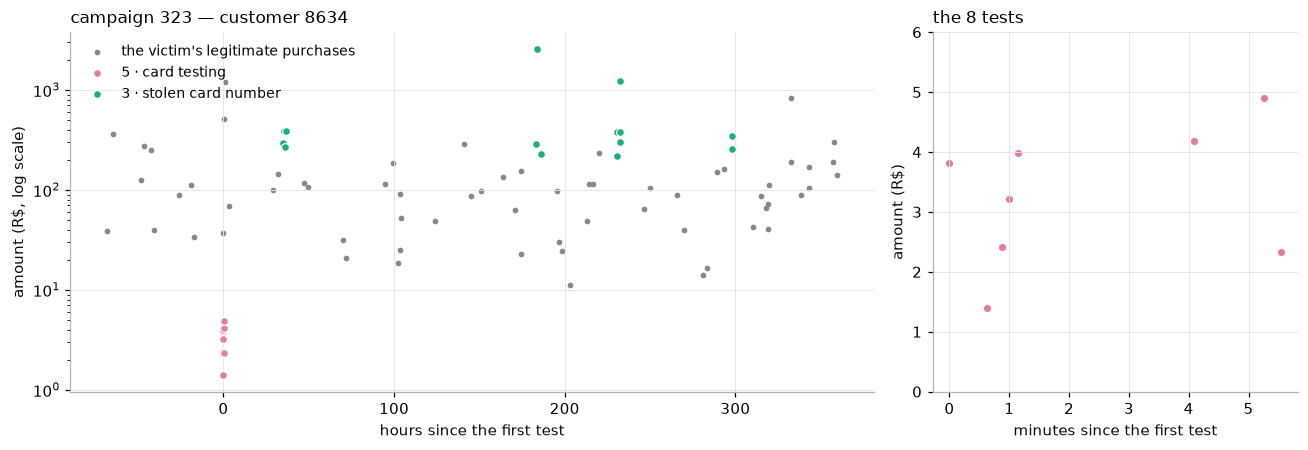

In [6]:
fig, (ax_all, ax_tests) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})

hours = lambda s: (s - t_first) / 3600  # noqa: E731
ax_all.scatter(hours(own.TX_TIME_SECONDS), own.TX_AMOUNT, s=14, color=MUTED, lw=0,
               label=T["victim_purchases"])
for scenario in (5, 3):
    part = campaign[campaign.TX_FRAUD_SCENARIO == scenario]
    ax_all.scatter(hours(part.TX_TIME_SECONDS), part.TX_AMOUNT, s=26, color=SCENARIO_COLORS[scenario],
                   edgecolor="#fcfcfb", lw=0.8, label=SCENARIO_NAMES[scenario], zorder=3)
ax_all.set_yscale("log")
ax_all.set_xlabel(T["hours_since_test"])
ax_all.set_ylabel(T["amount_log"])
ax_all.set_title(T["campaign_title"].format(campaign=campaign_id, customer=victim), loc="left", fontsize=11)
ax_all.legend(loc="upper left", frameon=False, fontsize=9)

tests = campaign[campaign.TX_FRAUD_SCENARIO == 5]
minutes = (tests.TX_TIME_SECONDS - t_first) / 60
ax_tests.scatter(minutes, tests.TX_AMOUNT, s=30, color=SCENARIO_COLORS[5], edgecolor="#fcfcfb", lw=0.8)
ax_tests.set_ylim(0, 6)
ax_tests.set_xlabel(T["minutes_since_test"])
ax_tests.set_ylabel(T["amount"])
ax_tests.set_title(T["tests_title"].format(n=len(tests)), loc="left", fontsize=11)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "frauds_card_testing_campaign.pdf", bbox_inches="tight")
plt.show()

## Points of compromise (scenario 2)

The compromised terminal makes no fraud: it reads the card of whoever buys there, and the
purchase stays legitimate. The ground truth marks that purchase with `GT_COMPROMISE_ID`,
and the frauds made later with the same card (cloned, in scenario 2, or just its number, in
scenario 3) carry the same id. `compromise_table` builds the table of compromises.

In [7]:
compromises = compromise_table(transactions)
use = compromises.USE_SCENARIO.map({2: "cloned (scenario 2)", 3: "leaked number (scenario 3)"})
print(f"{len(compromises):,} cards read at {compromises.TERMINAL_ID.nunique()} compromised terminals")
display(use.fillna("not used").value_counts().to_frame("cards"))
compromises.dropna(subset=["USE_SCENARIO"]).head()

1,236 cards read at 239 compromised terminals


,cards
USE_SCENARIO,
not used,948
cloned (scenario 2),235
leaked number (scenario 3),53


,GT_COMPROMISE_ID,CUSTOMER_ID,TERMINAL_ID,READ_TRANSACTION_ID,READ_DATETIME,GT_FRAUDSTER_ID,USE_SCENARIO,N_FRAUD_TX,FIRST_FRAUD_DATETIME
13,84,5378,8374,96274,2023-01-05 20:29:43,6,2,3,2023-01-15 10:58:27
18,64,2324,15884,115662,2023-01-06 18:38:46,5,2,5,2023-01-17 14:09:57
21,44,4836,177,120700,2023-01-06 21:51:03,4,2,1,2023-01-12 18:24:47
25,77,8409,15884,130383,2023-01-07 13:21:35,5,2,7,2023-01-15 09:50:59
26,5,949,8310,136437,2023-01-07 17:32:16,1,2,7,2023-01-18 14:55:29


## Amount per scenario

Distribution of the amounts of the legitimate transactions and of the frauds of each
scenario (log scale). The frauds of scenarios 1 to 4 are above the customer's pattern (those
of scenario 2 are purchases with the cloned card, as in scenario 4); those of scenario 5
are of R\$ 1 to 5.

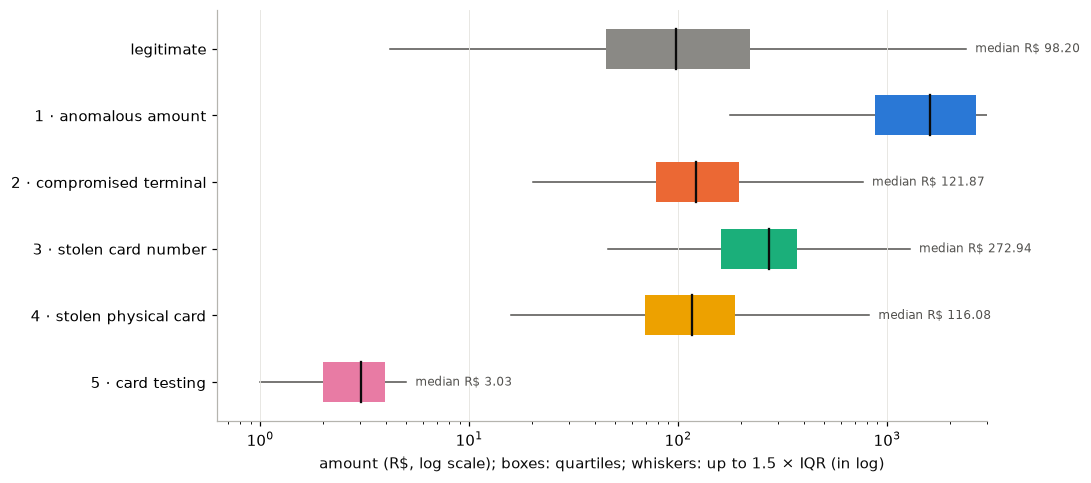

In [8]:
groups = [(T["legitimate"], transactions.loc[transactions.TX_FRAUD == 0, "TX_AMOUNT"], MUTED)]
groups += [(SCENARIO_NAMES[s], frauds.loc[frauds.TX_FRAUD_SCENARIO == s, "TX_AMOUNT"], SCENARIO_COLORS[s])
           for s in SCENARIO_NAMES]
groups = groups[::-1]  # legitimate on top

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (_, values, color) in enumerate(groups):
    # Box plot on the log scale: quartiles and whiskers computed on log10(amount)
    logs = np.log10(values[values > 0])
    q1, median, q3 = np.quantile(logs, [0.25, 0.5, 0.75])
    low = logs[logs >= q1 - 1.5 * (q3 - q1)].min()
    high = logs[logs <= q3 + 1.5 * (q3 - q1)].max()
    ax.plot([10**low, 10**high], [i, i], color=SECONDARY, lw=1, zorder=1)
    ax.barh(i, 10**q3 - 10**q1, left=10**q1, height=0.6, color=color, zorder=2)
    ax.plot([10**median] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5, zorder=3)
    ax.annotate(num(f"{T['median']} R$ {10**median:,.2f}"), (10**high, i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=SECONDARY)
ax.set_yticks(range(len(groups)), [g[0] for g in groups])
ax.set_xscale("log")
ax.set_xlim(right=3e3)
ax.set_xlabel(T["boxes_note"])
ax.grid(axis="y", visible=False)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "frauds_amount_by_scenario.pdf", bbox_inches="tight")
plt.show()

## Scenario 1 and drift: fixed-threshold label rule × injected fraud

A label rule with a fixed threshold (every transaction above R\$ 220 is fraud, as in the
simulator of the paper) labels legitimate purchases, and with drift it can mostly hit the
customers whose regime B spends more. We apply the R\$ 220 threshold directly to the
legitimate transactions and compare, in each dataset:

- the share of the legitimate transactions that come from regime B;
- the fixed-threshold label rule: which regime the transactions it would label come from;
- the injected fraud of scenario 1: which regime the victim was in on the day of the fraud
  (weight $w$ of regime B, from the customer's ground truth).

The comparison uses two datasets, with the same size and the same seed: the `drift` step of
the ablation (drift and seasonality, no merchants) and the complete dataset of this
notebook (with merchants). Without merchants, the amount of a purchase only depends on the
customer's regime; with merchants, it depends mostly on the category.

In [9]:
def victim_weight(row, profiles):
    # Weight of regime B for the victim of a fraud, on the day of the fraud
    profile = profiles.loc[row.CUSTOMER_ID]
    def value(name):
        return 0 if pd.isna(profile[name]) else int(profile[name])
    drift = CustomerDrift(kind=profile.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                          transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                          active_days=value("GT_DRIFT_ACTIVE_DAYS"))
    return regime_weight(drift, np.array([row.TX_TIME_DAYS + 0.5]))[0]


def regime_b_shares(profiles, data):
    # The three shares of regime B compared in the figure, and a sanity check
    legit = data[data.TX_FRAUD == 0]
    s1 = data[data.TX_FRAUD_SCENARIO == 1]
    over_threshold = legit[legit.TX_AMOUNT > 220]
    check = pd.Series({
        "scenario 1 transactions": len(s1),
        "of which legitimate transactions (with GT_REGIME)": int(s1.GT_REGIME.notna().sum()),
        "legitimate transactions labelled as fraud, in any scenario": int(
            (data.GT_REGIME.notna() & (data.TX_FRAUD == 1)).sum()
        ),
        "legitimate transactions above R$ 220": len(over_threshold),
    })
    shares = pd.Series({
        "legitimate transactions in regime B": (legit.GT_REGIME == "B").mean(),
        "fixed-threshold label rule (R$ 220): labelled, in regime B": (
            over_threshold.GT_REGIME == "B"
        ).mean(),
        "injected fraud (scenario 1): victims in regime B": s1.apply(
            victim_weight, axis=1, profiles=profiles
        ).mean(),
    })
    return check, shares


# The drift step of the ablation (no merchants), with the same size and seed
size = {k: PARAMS[k] for k in ("n_customers", "n_terminals", "nb_days", "start_date", "random_state")}
drift_customers, _, drift_transactions = DatasetGenerator(**presets.ablation("drift", **size)).generate()
DATASETS = {
    T["no_merchants"]: regime_b_shares(drift_customers, drift_transactions),
    T["full_dataset"]: regime_b_shares(customers, transactions),
}
del drift_customers, drift_transactions
display(pd.DataFrame({name: check for name, (check, _) in DATASETS.items()}))
(100 * pd.DataFrame({name: shares for name, (_, shares) in DATASETS.items()})).round(1)

,Without merchants,With merchants (full dataset)
scenario 1 transactions,578,527
of which legitimate transactions (with GT_REGIME),0,0
"legitimate transactions labelled as fraud, in any scenario",0,0
legitimate transactions above R$ 220,13859,933997


,Without merchants,With merchants (full dataset)
legitimate transactions in regime B,13.1,13.1
"fixed-threshold label rule (R$ 220): labelled, in regime B",86.0,13.9
injected fraud (scenario 1): victims in regime B,9.7,12.2


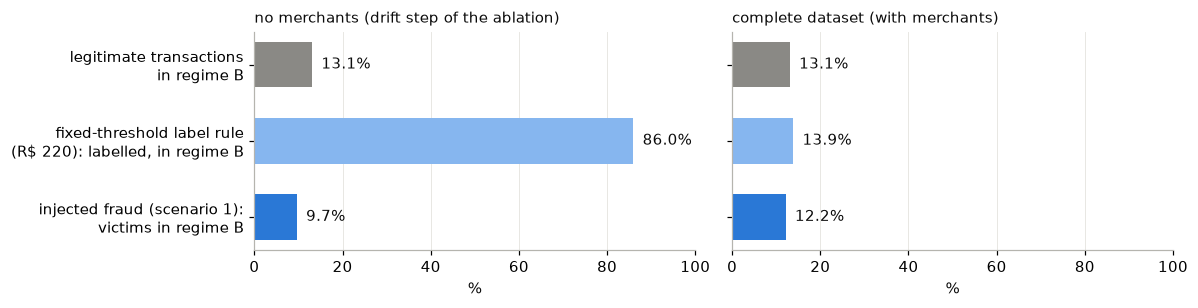

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9), sharey=True)
labels = T["share_labels"]
# Scenario 1 in its color; the threshold rule in a lighter step of the same hue
colors = [MUTED, "#86b6ef", SCENARIO_COLORS[1]]
y = np.arange(len(labels))[::-1]
for ax, (name, (_, shares)) in zip(axes, DATASETS.items()):
    values = 100 * shares.to_numpy()
    ax.barh(y, values, color=colors, height=0.6)
    for yi, value in zip(y, values):
        ax.annotate(num(f"{value:.1f}%"), (value, yi), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=10, color=INK)
    ax.set_title(name, fontsize=10, color=INK, loc="left")
    ax.set_xlim(0, 100)
    ax.set_xlabel("%")
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
axes[0].set_yticks(y, labels)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "frauds_scenario1_regime_b.pdf", bbox_inches="tight")
plt.show()

## View by category (with merchants)

With merchants (`MerchantConfig`), each scenario buys in its own categories
(`presets.realistic()` has merchants; with a preset without them, the notebook generates
the same data with merchants):

- **scenario 1:** high-amount categories (electronics, travel);
- **scenario 2:** the whole merchant is compromised, chosen by the risk of its category
  (fuel station 3, restaurant 2, others 1), and the cloned card is used in resellable
  categories;
- **scenario 3:** resellable or digital categories, with amounts above the category's
  median. In `FraudConfig.realistic()`, it migrates from electronics to digital services
  from 50% of the period on;
- **scenario 4:** resellable categories (electronics, fuel station, pharmacy, supermarket),
  only with the merchant open;
- **scenario 5:** digital services.

fraud rate with merchants: 0.356%


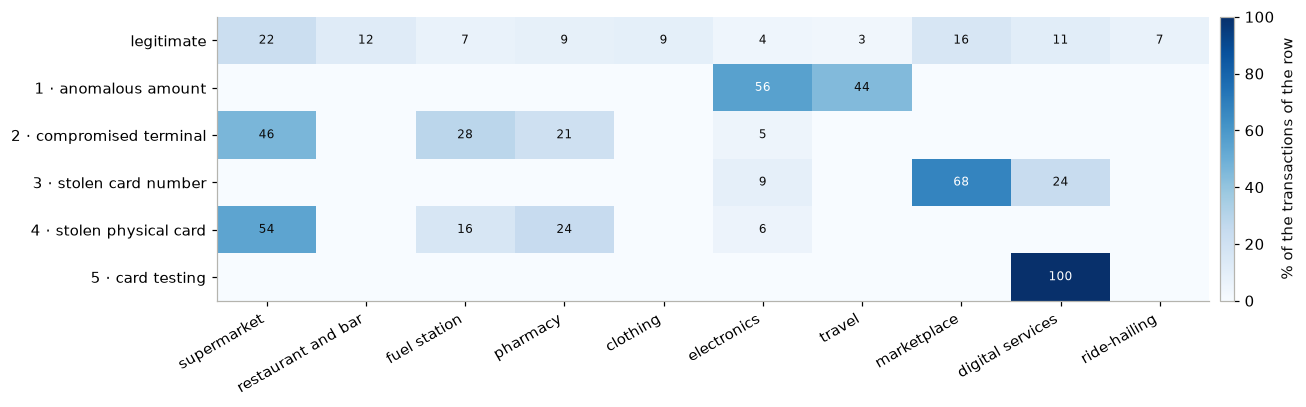

In [11]:
if PARAMS.get("merchants") is not None:
    shop_terminals, shop_tx = terminals, transactions
else:
    _, shop_terminals, shop_tx = DatasetGenerator(**{**PARAMS, "merchants": MerchantConfig()}).generate()
CATEGORY_NAMES = list((PARAMS.get("merchants") or MerchantConfig()).names)
group = shop_tx.TX_FRAUD_SCENARIO.map(lambda s: T["legitimate"] if s == 0 else SCENARIO_NAMES[s])
table = pd.crosstab(group, shop_tx.MERCHANT_CATEGORY, normalize="index").reindex(
    index=[T["legitimate"], *SCENARIO_NAMES.values()], columns=CATEGORY_NAMES, fill_value=0
)
print(f"fraud rate with merchants: {shop_tx.TX_FRAUD.mean():.3%}")

fig, ax = plt.subplots(figsize=(12, 3.8))
image = ax.imshow(100 * table.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=100)
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        value = 100 * table.iat[i, j]
        if value >= 1:
            ax.text(j, i, f"{value:.0f}", ha="center", va="center", fontsize=8,
                    color="#ffffff" if value > 55 else INK)
ax.set_xticks(range(len(CATEGORY_NAMES)), [T["categories"].get(n, n) for n in CATEGORY_NAMES], rotation=30, ha="right")
ax.set_yticks(range(len(table)), table.index)
ax.grid(False)
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.01)
colorbar.set_label(T["share_of_row"])
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "frauds_category_by_scenario.pdf", bbox_inches="tight")
plt.show()

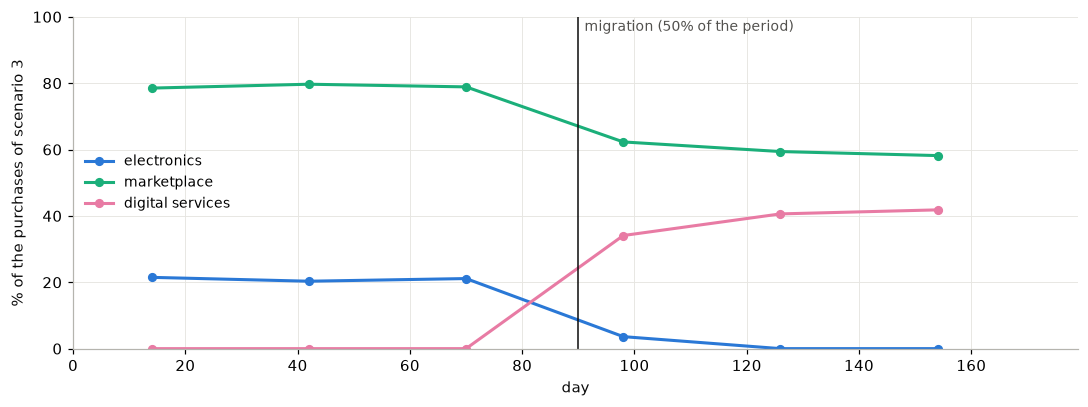

In [12]:
# Scenario 3 over time: share of its purchases in each category, per 4 weeks (the
# last, partial block is left out)
s3 = shop_tx[(shop_tx.TX_FRAUD_SCENARIO == 3) & (shop_tx.TX_TIME_DAYS < NB_DAYS // 28 * 28)]
block = s3.TX_TIME_DAYS // 28
s3_shares = pd.crosstab(block, s3.MERCHANT_CATEGORY, normalize="index")
s3_colors = {"eletronicos": SCENARIO_COLORS[1], "ecommerce_marketplace": SCENARIO_COLORS[3],
             "servicos_digitais": SCENARIO_COLORS[5]}
fig, ax = plt.subplots(figsize=(10, 3.8))
x = s3_shares.index * 28 + 14
for name, color in s3_colors.items():
    values = 100 * s3_shares.get(name, pd.Series(0.0, index=s3_shares.index))
    ax.plot(x, values, color=color, lw=2, marker="o", markersize=5, label=T["categories"].get(name, name))
ax.axvline(0.5 * NB_DAYS, color=INK, lw=1)
ax.annotate(T["migration"], (0.5 * NB_DAYS, 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color=SECONDARY)
ax.set_xlim(0, NB_DAYS - 1)
ax.set_ylim(0, 100)
ax.set_xlabel(T["day"])
ax.set_ylabel(T["share_of_s3"])
ax.legend(loc="center left", frameon=False, fontsize=9)
fig.tight_layout()
localize(fig)
fig.savefig(FIG_DIR / "frauds_scenario3_migration.pdf", bbox_inches="tight")
plt.show()